In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

In [2]:
df=pd.read_csv("C:/Users/MAREY/Downloads/heart_failure/heart.csv")

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


## use one-hot encoding to convert the categorical variable to numraical variables

In [4]:
cat_variables=['Sex','ChestPainType','RestingECG','ExerciseAngina','ST_Slope']

In [5]:
df=pd.get_dummies(data=df,prefix=cat_variables,columns=cat_variables)

In [6]:
df.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,False,True,False,...,False,False,False,True,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,True,False,False,...,True,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,48,138,214,0,108,1.5,1,True,False,True,...,False,False,False,True,False,False,True,False,True,False
4,54,150,195,0,122,0.0,0,False,True,False,...,True,False,False,True,False,True,False,False,False,True


In [7]:
x=df.drop(columns='HeartDisease')
y=df['HeartDisease']

In [8]:
print(x,y)

     Age  RestingBP  Cholesterol  FastingBS  MaxHR  Oldpeak  Sex_F  Sex_M  \
0     40        140          289          0    172      0.0  False   True   
1     49        160          180          0    156      1.0   True  False   
2     37        130          283          0     98      0.0  False   True   
3     48        138          214          0    108      1.5   True  False   
4     54        150          195          0    122      0.0  False   True   
..   ...        ...          ...        ...    ...      ...    ...    ...   
913   45        110          264          0    132      1.2  False   True   
914   68        144          193          1    141      3.4  False   True   
915   57        130          131          0    115      1.2  False   True   
916   57        130          236          0    174      0.0   True  False   
917   38        138          175          0    173      0.0  False   True   

     ChestPainType_ASY  ChestPainType_ATA  ChestPainType_NAP  \
0          

## spilt the dataset

In [9]:
x_train,x_val,y_train,y_val=train_test_split(x,y,test_size=0.2,random_state=42)

In [10]:
print(len(x_train),len(x_val))

734 184


## train the model(DecisionTree)

In [12]:
min_samples_split_list = [2,10, 30, 50, 100, 200, 300, 700]
max_depth_list = [1,2, 3, 4, 8, 16, 32, 64] 

([<matplotlib.axis.XTick at 0x19b03438690>,
 [Text(0, 0, '2'),
  Text(1, 0, '10'),
  Text(2, 0, '30'),
  Text(3, 0, '50'),
  Text(4, 0, '100'),
  Text(5, 0, '200'),
  Text(6, 0, '300'),
  Text(7, 0, '700')])

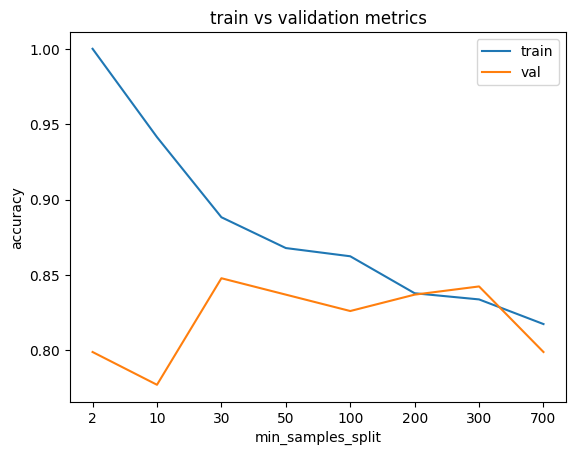

In [14]:
accurcy_list_train=[]
accuracy_list_val=[]
for min_samples_split in min_samples_split_list:
    model=DecisionTreeClassifier(min_samples_split=min_samples_split,random_state=42).fit(x_train,y_train)
    predictions_train=model.predict(x_train) ## the prediction values for train dataset
    predictions_val=model.predict(x_val) ## the prediction values for test dataset
    accuracy_train=accuracy_score(predictions_train,y_train)
    accuracy_val=accuracy_score(predictions_val,y_val)
    accurcy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)
plt.title("train vs validation metrics")
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.plot(accurcy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['train','val'])
plt.xticks(ticks=range(len(min_samples_split_list)),
    labels=min_samples_split_list
)

([<matplotlib.axis.XTick at 0x19b03483610>,
 [Text(0, 0, '1'),
  Text(1, 0, '2'),
  Text(2, 0, '3'),
  Text(3, 0, '4'),
  Text(4, 0, '8'),
  Text(5, 0, '16'),
  Text(6, 0, '32'),
  Text(7, 0, '64')])

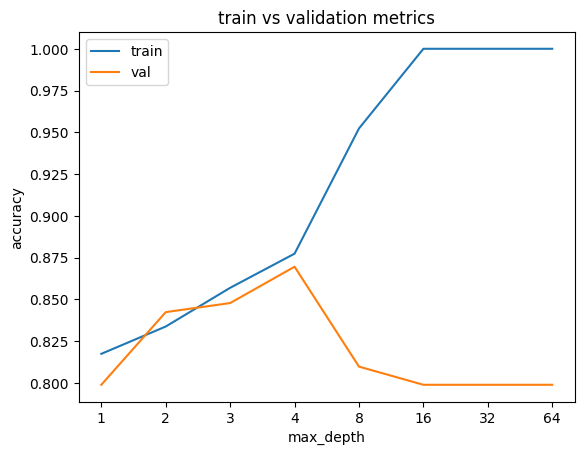

In [15]:
accurcy_list_train=[]
accuracy_list_val=[]
for max_depth in max_depth_list:
    model=DecisionTreeClassifier(max_depth=max_depth,random_state=42).fit(x_train,y_train)
    predictions_train=model.predict(x_train) ## the prediction values for train dataset
    predictions_val=model.predict(x_val) ## the prediction values for test dataset
    accuracy_train=accuracy_score(predictions_train,y_train)
    accuracy_val=accuracy_score(predictions_val,y_val)
    accurcy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)
plt.title("train vs validation metrics")
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.plot(accurcy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['train','val'])
plt.xticks(ticks=range(len(max_depth_list)),
    labels=max_depth_list
)

In [16]:
# the best choice here is min_samples_split=30 and max_depth=4

In [17]:
decision_tree_model=DecisionTreeClassifier(min_samples_split=30,max_depth=4,random_state=42).fit(x_train,y_train)

In [20]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(x_train),y_train):.4f}")
print(f"Metrics validation:\n\tAccuracy score: {accuracy_score(decision_tree_model.predict(x_val),y_val):.4f}")

Metrics train:
	Accuracy score: 0.8706
Metrics validation:
	Accuracy score: 0.8696


## RandomForst

In [24]:
min_samples_split_list = [2,10, 30, 50, 100, 200, 300, 700]
max_depth_list = [1,2, 3, 4, 8, 16, 32, 64]
n_estimators_list = [10,50,100,500]

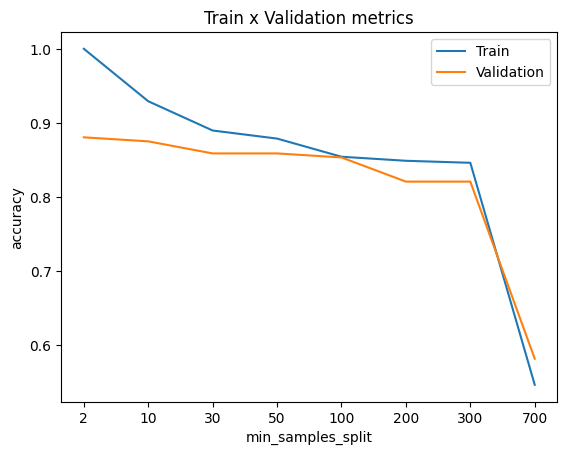

In [26]:
accuracy_list_train = []
accuracy_list_val = []
for min_samples_split in min_samples_split_list:
    model = RandomForestClassifier(min_samples_split = min_samples_split, random_state = 42).fit(x_train,y_train)
    predictions_train = model.predict(x_train) ## The predicted values for the train dataset
    predictions_val = model.predict(x_val) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_val = accuracy_score(predictions_val,y_val)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)
plt.title('Train x Validation metrics')
plt.xlabel('min_samples_split')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(min_samples_split_list )),labels=min_samples_split_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train', 'Validation'])

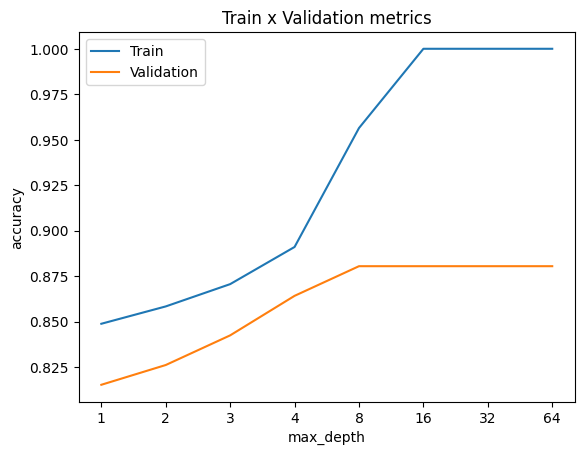

In [29]:
accuracy_list_train = []
accuracy_list_val = []
for max_depth in max_depth_list:
    model = RandomForestClassifier(max_depth =max_depth, random_state = 42).fit(x_train,y_train)
    predictions_train = model.predict(x_train) ## The predicted values for the train dataset
    predictions_val = model.predict(x_val) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_val = accuracy_score(predictions_val,y_val)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)
plt.title('Train x Validation metrics')
plt.xlabel('max_depth')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(max_depth_list )),labels=max_depth_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train', 'Validation'])

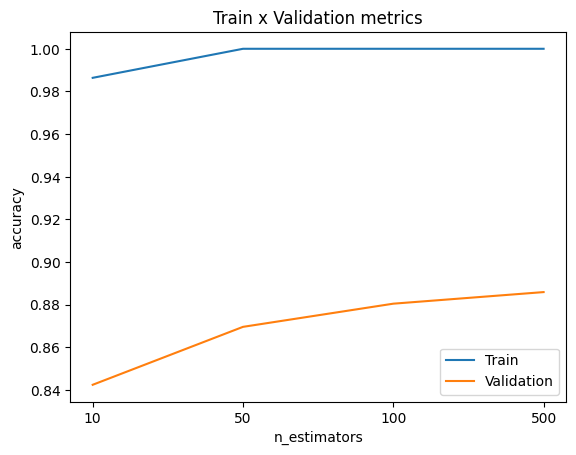

In [30]:
accuracy_list_train = []
accuracy_list_val = []
for n_estimators in n_estimators_list:
    model = RandomForestClassifier(n_estimators =n_estimators, random_state = 42).fit(x_train,y_train)
    predictions_train = model.predict(x_train) ## The predicted values for the train dataset
    predictions_val = model.predict(x_val) ## The predicted values for the test dataset
    accuracy_train = accuracy_score(predictions_train,y_train)
    accuracy_val = accuracy_score(predictions_val,y_val)
    accuracy_list_train.append(accuracy_train)
    accuracy_list_val.append(accuracy_val)
plt.title('Train x Validation metrics')
plt.xlabel('n_estimators')
plt.ylabel('accuracy')
plt.xticks(ticks = range(len(n_estimators_list )),labels=n_estimators_list)
plt.plot(accuracy_list_train)
plt.plot(accuracy_list_val)
plt.legend(['Train', 'Validation'])

In [32]:
random_forest_model = RandomForestClassifier(n_estimators = 100,
                                             max_depth = 16,
                                             min_samples_split = 10).fit(x_train,y_train)

In [34]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(x_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(random_forest_model.predict(x_val),y_val):.4f}")

Metrics train:
	Accuracy score: 0.9278
Metrics test:
	Accuracy score: 0.8804


 ## XGBoost

In [36]:
n = int(len(x_train)*0.8) ## Let's use 80% to train and 20% to eval

x_train_fit,x_train_eval, y_train_fit, y_train_eval = x_train[:n], x_train[n:], y_train[:n], y_train[n:]

In [41]:
xgb_model = XGBClassifier(n_estimators = 500, learning_rate = 0.1,verbosity = 1, random_state = 42,early_stopping_rounds = 10)
xgb_model.fit(x_train_fit,y_train_fit, eval_set = [(x_train_eval,y_train_eval)])

[0]	validation_0-logloss:0.65147
[1]	validation_0-logloss:0.61294
[2]	validation_0-logloss:0.57975
[3]	validation_0-logloss:0.55176
[4]	validation_0-logloss:0.53179
[5]	validation_0-logloss:0.51404
[6]	validation_0-logloss:0.49887
[7]	validation_0-logloss:0.48811
[8]	validation_0-logloss:0.47910
[9]	validation_0-logloss:0.47019
[10]	validation_0-logloss:0.46102
[11]	validation_0-logloss:0.45350
[12]	validation_0-logloss:0.44869
[13]	validation_0-logloss:0.44373
[14]	validation_0-logloss:0.44140
[15]	validation_0-logloss:0.43771
[16]	validation_0-logloss:0.43603
[17]	validation_0-logloss:0.43263
[18]	validation_0-logloss:0.43099
[19]	validation_0-logloss:0.42716
[20]	validation_0-logloss:0.42804
[21]	validation_0-logloss:0.42717
[22]	validation_0-logloss:0.42610
[23]	validation_0-logloss:0.42524
[24]	validation_0-logloss:0.42592
[25]	validation_0-logloss:0.42088
[26]	validation_0-logloss:0.41736
[27]	validation_0-logloss:0.41674
[28]	validation_0-logloss:0.41551
[29]	validation_0-loglos

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",10
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [42]:
xgb_model.best_iteration

29

In [44]:
print(f"Metrics train:\n\tAccuracy score: {accuracy_score(xgb_model.predict(x_train),y_train):.4f}\nMetrics test:\n\tAccuracy score: {accuracy_score(xgb_model.predict(x_val),y_val):.4f}")

Metrics train:
	Accuracy score: 0.9387
Metrics test:
	Accuracy score: 0.8696
